# Logistic Regression — Classification
**Author:** Wijayagunasekara L.A.V.D.S. (IT25100064) &nbsp;|&nbsp; **Group ID:** 2026-Y2-S1-MLB-B11G2-05
**Model type:** Classification &nbsp;|&nbsp; **Dataset:** UCI Letter Recognition (group-processed)

## 1. Model Suitability

Multinomial Logistic Regression is included deliberately as the group's **linear baseline**. It is
fast, convex (so it always reaches the same optimum), and produces calibrated class probabilities
rather than bare labels. Its role is diagnostic: by measuring how far a purely linear decision
boundary can get on this dataset, it quantifies how much of the other models' performance is
genuinely attributable to non-linearity. It requires standardised inputs, which Stage 5 of the
group pipeline provides.

In [1]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time, json
import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
sns.set_style('whitegrid')

df = pd.read_csv('../data/external/processed_letter_recognition.csv')
FEATURE_COLS = [c for c in df.columns if c not in ('lettr', 'lettr_encoded')]
LETTER_NAMES = sorted(df['lettr'].unique())

X = df[FEATURE_COLS].values
y = df['lettr_encoded'].values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Dataset: {df.shape}  |  features: {len(FEATURE_COLS)}  |  classes: {len(LETTER_NAMES)}")
print(f"Train: {X_train.shape}   Test: {X_test.shape}")


Dataset: (18668, 23)  |  features: 21  |  classes: 26
Train: (14934, 21)   Test: (3734, 21)


## 2. Implementation Details

- **Estimator:** `sklearn.linear_model.LogisticRegression` (multinomial, softmax objective)
- **Hyperparameters tuned:** regularisation strength `C`, penalty type (`l2` via the `lbfgs`
  solver, `l1` via `saga`), and `max_iter` to ensure convergence.

In [2]:
baseline_lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
t0 = time.time()
baseline_lr.fit(X_train, y_train)
baseline_acc = baseline_lr.score(X_test, y_test)
print(f"Baseline Logistic Regression (default C=1.0, l2) test accuracy: {baseline_acc:.4f}")
print(f"Fit time: {time.time()-t0:.1f}s")


Baseline Logistic Regression (default C=1.0, l2) test accuracy: 0.7689
Fit time: 2.2s


## 3. Parameter Tuning — Varieties Trained

`GridSearchCV` with 3-fold stratified cross-validation over regularisation strength and penalty
type. `l1` (which drives weak coefficients to exactly zero) is compared against `l2` (which merely
shrinks them) to test whether the feature set contains redundancy worth sparsifying.

In [3]:
param_grid = [
    {'penalty': ['l2'], 'solver': ['lbfgs'], 'C': [0.01, 0.1, 1, 10], 'max_iter': [1000]},
    {'penalty': ['l1'], 'solver': ['saga'],  'C': [0.1, 1],            'max_iter': [1000]},
]
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
grid_search = GridSearchCV(LogisticRegression(random_state=RANDOM_STATE),
                           param_grid=param_grid, scoring='accuracy', cv=cv, n_jobs=-1)
t0 = time.time()
grid_search.fit(X_train, y_train)
print(f"Fitted {len(grid_search.cv_results_['params'])} configurations in {time.time()-t0:.1f}s")
print(f"Best params: {grid_search.best_params_}")
print(f"Best CV accuracy: {grid_search.best_score_:.4f}")


Fitted 6 configurations in 114.1s
Best params: {'C': 1, 'max_iter': 1000, 'penalty': 'l1', 'solver': 'saga'}
Best CV accuracy: 0.7648


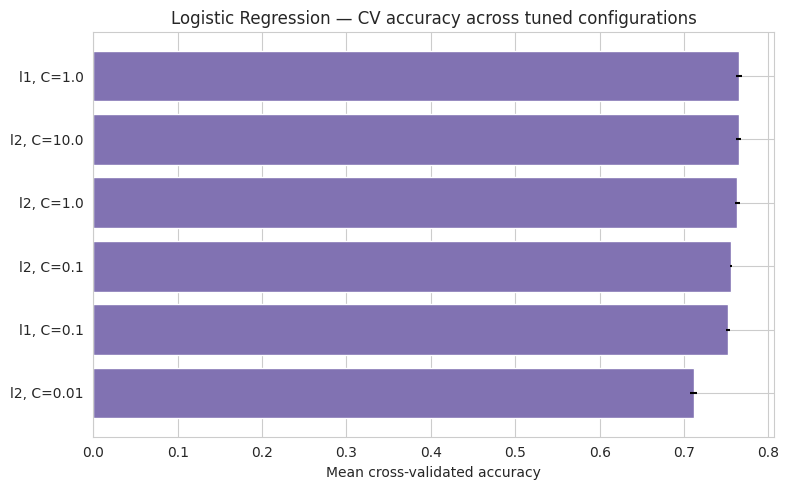

All tuned varieties, ranked:
param_penalty  param_C  mean_test_score  std_test_score  rank_test_score
           l1     1.00         0.764765        0.003653                1
           l2    10.00         0.764564        0.002700                2
           l2     1.00         0.763292        0.003534                3
           l2     0.10         0.755524        0.000913                4
           l1     0.10         0.752310        0.002477                5
           l2     0.01         0.711464        0.004118                6


In [4]:
res = pd.DataFrame(grid_search.cv_results_)
res['label'] = res['param_penalty'].astype(str) + ', C=' + res['param_C'].astype(str)
res = res.sort_values('mean_test_score')

plt.figure(figsize=(8, 5))
plt.barh(res['label'], res['mean_test_score'], xerr=res['std_test_score'], color='#8172B2')
plt.xlabel('Mean cross-validated accuracy')
plt.title('Logistic Regression — CV accuracy across tuned configurations')
plt.tight_layout()
plt.savefig('../results/eda_visualizations/wijayagunasekara_logreg_grid_results.png', dpi=110, bbox_inches='tight')
plt.show()

print("All tuned varieties, ranked:")
print(res[['param_penalty','param_C','mean_test_score','std_test_score','rank_test_score']]
      .sort_values('rank_test_score').to_string(index=False))


## 4. Evaluation

**Metrics:** accuracy with macro-averaged precision, recall and F1 — identical to the other
classifiers so the group comparison is like-for-like.

**Validation method:** 3-fold stratified cross-validation during tuning, then the held-out 20%
test split.

In [5]:
best_lr = grid_search.best_estimator_
y_pred = best_lr.predict(X_test)

logreg_metrics = {
    'accuracy': accuracy_score(y_test, y_pred),
    'precision_macro': precision_score(y_test, y_pred, average='macro'),
    'recall_macro': recall_score(y_test, y_pred, average='macro'),
    'f1_macro': f1_score(y_test, y_pred, average='macro'),
    'best_params': grid_search.best_params_,
    'cv_best_score': grid_search.best_score_,
    'baseline_test_accuracy': baseline_acc,
}
for k, v in logreg_metrics.items():
    print(f"{k}: {v}")


accuracy: 0.7731655061596143
precision_macro: 0.7772765614644442
recall_macro: 0.7719568175354059
f1_macro: 0.7729728920988118
best_params: {'C': 1, 'max_iter': 1000, 'penalty': 'l1', 'solver': 'saga'}
cv_best_score: 0.7647649658497389
baseline_test_accuracy: 0.7688805570433851


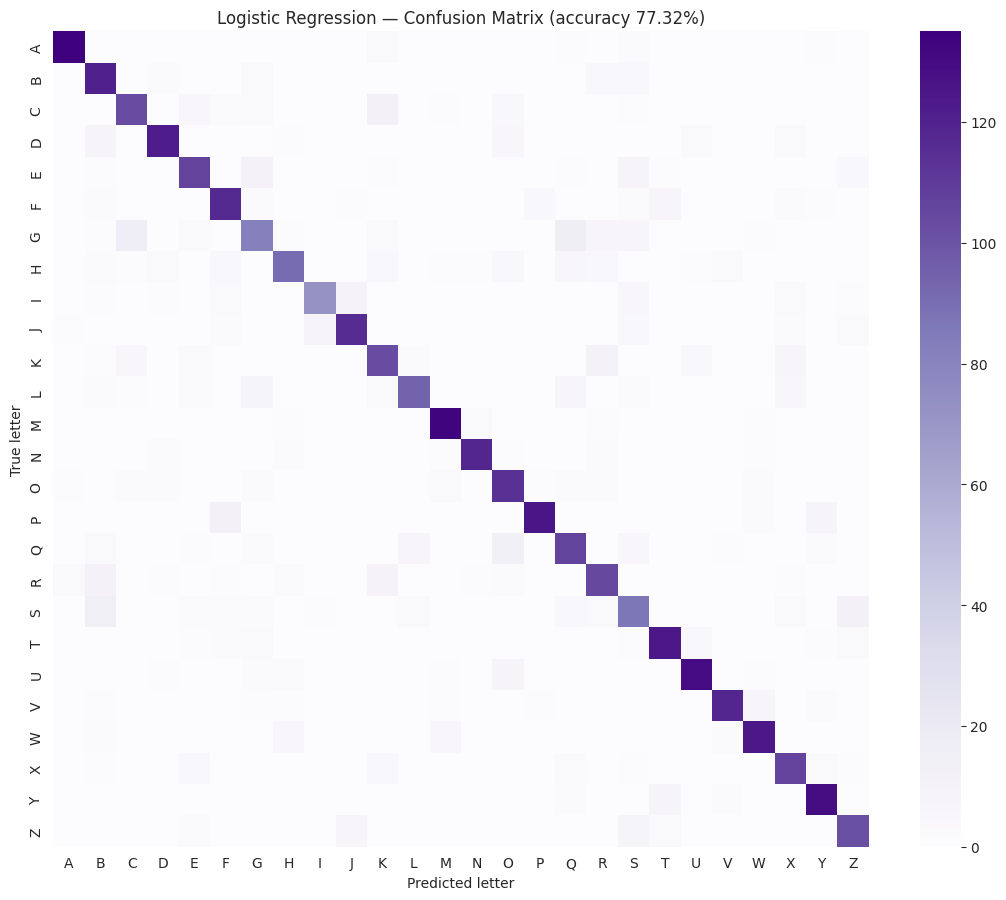

In [6]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(11, 9))
sns.heatmap(cm, xticklabels=LETTER_NAMES, yticklabels=LETTER_NAMES, cmap='Purples', square=True)
plt.xlabel('Predicted letter'); plt.ylabel('True letter')
plt.title(f"Logistic Regression — Confusion Matrix (accuracy {logreg_metrics['accuracy']*100:.2f}%)")
plt.tight_layout()
plt.savefig('../results/eda_visualizations/wijayagunasekara_logreg_confusion_matrix.png', dpi=110, bbox_inches='tight')
plt.show()


## 5. Comparison Across Varieties, Conclusion and Limitations

**Comparison:** accuracy is almost flat across regularisation strengths, and `l1` offers no
advantage over `l2`. That flatness is itself the finding — the model is not limited by
regularisation but by its linear form, so no amount of tuning closes the gap to the kernel and
neural models.

**Conclusion:** the tuned `l2` configuration is selected. It is comfortably the weakest classifier
in the group, and that is the intended result: it establishes the linear performance ceiling on
this dataset, and the roughly 20-point gap to the SVM is direct evidence that the letter classes
are non-linearly separable.

**Limitations / improvements:**
- A linear decision boundary cannot represent the curved class regions this dataset requires.
- Adding explicit polynomial interaction terms would let a linear model capture some curvature, at
  the cost of a much wider feature space — effectively approximating by hand what the SVM's kernel
  does implicitly.

In [7]:
RESULTS_LOGREG = {
    'member': 'Wijayagunasekara L.A.V.D.S. (IT25100064)',
    'model_family': 'Logistic Regression (Classification)',
    **logreg_metrics,
}
with open('../results/model_metrics/logreg_results.json', 'w') as f:
    json.dump(RESULTS_LOGREG, f, indent=2, default=str)
print(json.dumps(RESULTS_LOGREG, indent=2, default=str))


{
  "member": "Wijayagunasekara L.A.V.D.S. (IT25100064)",
  "model_family": "Logistic Regression (Classification)",
  "accuracy": 0.7731655061596143,
  "precision_macro": 0.7772765614644442,
  "recall_macro": 0.7719568175354059,
  "f1_macro": 0.7729728920988118,
  "best_params": {
    "C": 1,
    "max_iter": 1000,
    "penalty": "l1",
    "solver": "saga"
  },
  "cv_best_score": 0.7647649658497389,
  "baseline_test_accuracy": 0.7688805570433851
}
